# 2.2 Model interrogation

In [1]:
#__ Import: Numerical __
import numpy as np

#__ Import: Topophone2 __
from topophone2.topophone import decompose
from topophone2.inversion import MarginalStats
from topophone2.utils.read import read_txt

#__ Import: Plotting __
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import matplotlib.ticker as ticker
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cmcrameri.cm as cmc

#__ Set up: Plotting __
theme = ['#DC4424', '#74A466', '#24448C', '#F8BC5C']
small, large = 8, 10
plt.rcParams["font.sans-serif"] = ['Arial']

#__ Set up: Random seed __
np.random.seed(2026)

Hello from topophone2!


### 2.2.1 Load example data

In [2]:
#__ Read: Signal + noise __
out = read_txt("../data/hukkakero/signal_topophone2.txt")
freq_Hz   = out[0]  # Frequency vector         [Hz]       (frequency)
x         = out[1]  # Receiver position        [m]        (receiver, direction)
Gamma_obs = out[2]  # Array-covariance matrix  [Pa2.Hz-1] (frequency, receiver, receiver)
N_obs     = out[3]  # Independent observations
freq      = 2 * np.pi * freq_Hz  # Angular frequency vector [rad.s-1] (frequency)

#__ Read: Noise only __
out = read_txt("../data/hukkakero/noise_topophone2.txt")
Gamma_obs_noise = out[2]  # Array-covariance matrix  [Pa2.Hz-1] (frequency, receiver, receiver)
N_obs_noise     = out[3]  # Independent observations

### 2.2.2 Invert example data

Set inversion parameters...

In [3]:
#__ Signals present __
sigs = [
    'isoselfnoise', {'sig':'noise2D', 'max_order':2}
]

#__ Prior bounds: [w_self, w_noise, s, a1, a2, b1, b2] __
lower = np.array([-55., -55., 2.2e-3, 0.1, -0.35, -0.55, -0.35])
upper = np.array([-45., -45., 2.5e-3, 0.3, -0.15, -0.30, -0.15])

#__ max_order = 3 __
# h     = np.array([0.81, 0.5, 0.5])
# lower = np.concatenate([[-80., -80., 2.0e-3], -h, -h])
# upper = np.concatenate([[-40., -40., 3.1e-3],  h,  h])

#__ Number of flows __
N_flow = 8

#__ Inversion parameters __
learning_rate = 5e-4                       # Learning rate for the optimiser
N_iterations  = 30000                      # Number of iterations for optimiser
N_montecarlo  = 50                        # Number of samples to estimate ELBO

#__ Number of samples to draw __
N_samples = 20000

In [4]:
#__ Perform inversion __
decompose(
    Gamma_obs       = Gamma_obs_noise,
    N_obs           = N_obs_noise,
    x               = x,
    freq            = freq,
    sigs            = sigs,
    prior_bounds    = (lower,upper),
    N_flow          = N_flow,
    learning_rate   = learning_rate,
    outpath         = "../models/hukkakero",
    N_iterations    = N_iterations,
    N_montecarlo    = N_montecarlo,
    N_out           = 10,
    verbose         = True,
    N_samples       = N_samples
)

#__ Read results __
m = np.loadtxt(f"../models/hukkakero/model-samples_iteration-{N_iterations:05d}.txt")

----------------------------------------

Iteration:     0,	Loss:  -14788.90
The elapsed time is: 0.03 s
Iteration:  3000,	Loss:  -20142.99
The elapsed time is: 73.78 s
Iteration:  6000,	Loss:  -20145.76
The elapsed time is: 147.51 s
Iteration:  9000,	Loss:  -20149.09
The elapsed time is: 222.11 s
Iteration: 12000,	Loss:  -20150.38
The elapsed time is: 296.22 s
Iteration: 15000,	Loss:  -20150.26
The elapsed time is: 370.74 s
Iteration: 18000,	Loss:  -20150.56
The elapsed time is: 444.60 s
Iteration: 21000,	Loss:  -20150.07
The elapsed time is: 518.64 s
Iteration: 24000,	Loss:  -20150.40
The elapsed time is: 592.88 s
Iteration: 27000,	Loss:  -20150.59
The elapsed time is: 666.82 s
Iteration: 30000,	Loss:  -20150.34
The elapsed time is: 740.99 s
----------------------------------------

Finish training!


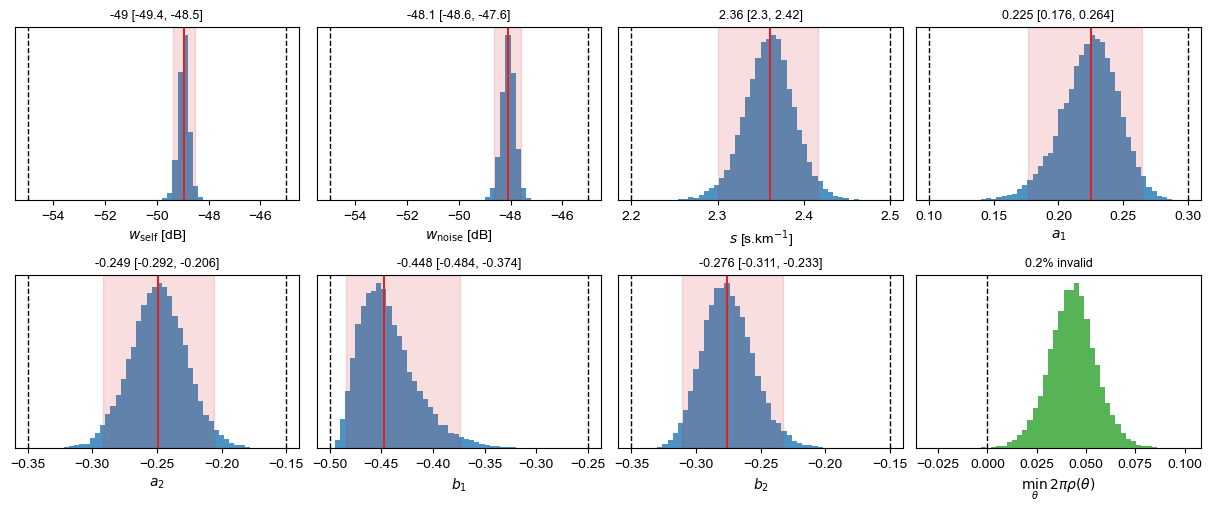

In [5]:
#__ Harmonic order from model vector: [w_self, w_noise, s, a_1..a_M, b_1..b_M] __
N_param = m.shape[1]
M       = (N_param - 3) // 2

#__ Parameter labels and display scaling __
labels = ([r'$w_\mathrm{self}$ [dB]', r'$w_\mathrm{noise}$ [dB]', r'$s$ [s.km$^{-1}$]']
          + [rf'$a_{k}$' for k in range(1, M+1)]
          + [rf'$b_{k}$' for k in range(1, M+1)])
scale  = np.ones(N_param) ; scale[2] = 1e3   # Slowness shown in s.km-1

#__ Set up figure (one extra panel for positivity check) __
N_panel = N_param + 1
N_col   = int(np.ceil(N_panel / 2))
fig, axes = plt.subplots(2, N_col, figsize=(3*N_col, 5), constrained_layout=True)
axes = axes.ravel()

#__ Plot each marginal __
for k in range(N_param):
    ax  = axes[k]
    m_k = m[:, k] * scale[k]
    lo, hi = lower[k] * scale[k], upper[k] * scale[k]

    #__ Histogram over the prior range __
    ax.hist(m_k, bins=50, range=(lo, hi), density=True, color='C0', alpha=0.8)

    #__ Prior bounds __
    ax.axvline(lo, color='k', ls='--', lw=1)
    ax.axvline(hi, color='k', ls='--', lw=1)

    #__ Median and 95% credible interval __
    q025, q50, q975 = np.percentile(m_k, [2.5, 50, 97.5])
    ax.axvline(q50, color='C3', lw=1.5)
    ax.axvspan(q025, q975, color='C3', alpha=0.15)

    #__ Labels __
    ax.set_xlabel(labels[k])
    ax.set_yticks([])
    ax.set_title(f'{q50:.3g} [{q025:.3g}, {q975:.3g}]', fontsize=9)

#__ Positivity check: minimum of 2*pi*rho(theta) over azimuth __
theta   = np.linspace(0, 2*np.pi, 361)
orders  = np.arange(1, M+1)
basis   = np.vstack([np.cos(orders[:,None]*theta), np.sin(orders[:,None]*theta)])  # (2M, theta)
rho_min = (1 + 2 * m[:, 3:3+2*M] @ basis).min(axis=1)

ax = axes[N_param]
ax.hist(rho_min, bins=50, density=True, color='C2', alpha=0.8)
ax.axvline(0, color='k', ls='--', lw=1)
ax.set_xlabel(r'$\min_\theta\, 2\pi\rho(\theta)$')
ax.set_yticks([])
ax.set_title(f'{100*np.mean(rho_min < 0):.1f}% invalid', fontsize=9)

#__ Hide unused panels __
for ax in axes[N_panel:]: ax.set_visible(False)

plt.show()

In [34]:
#__ Signals present __
sigs = [
    'skewnormal',
    'isoselfnoise',
    {'sig':'noise2D', 'max_order':2}
]

#__ Prior bounds __
lower = np.array([
    -40., -2.7e-3, 1.0e-3, 1e-6, 1e-6, -0.9, -5., -5.,
    -55.,
    -55., 2.2e-3, 0.1, -0.35, -0.55, -0.35
])
upper = np.array([
    -30., -2.2e-3, 1.6e-3, 1e-3, 1e-3,  0.9,  5.,  5.,
    -45.,
    -45., 2.5e-3, 0.3, -0.15, -0.30, -0.15
])

#__ Number of flows __
N_flow = 8

#__ Inversion parameters __
learning_rate = 5e-4                       # Learning rate for the optimiser
N_iterations  = 20000                      # Number of iterations for optimiser
N_montecarlo  = 50                        # Number of samples to estimate ELBO

#__ Number of samples to draw __
N_samples = 20000

In [35]:
#__ Perform inversion __
decompose(
    Gamma_obs       = Gamma_obs,
    N_obs           = N_obs,
    Gamma_obs_noise = Gamma_obs_noise,
    N_obs_noise     = N_obs_noise,
    x               = x,
    freq            = freq,
    sigs            = sigs,
    prior_bounds    = (lower,upper),
    N_flow          = N_flow,
    learning_rate   = learning_rate,
    outpath         = "../models/hukkakero",
    N_iterations    = N_iterations,
    N_montecarlo    = N_montecarlo,
    N_out           = 10,
    verbose         = True,
    N_samples       = N_samples
)

#__ Read results __
m = np.loadtxt(f"../models/hukkakero/model-samples_iteration-{N_iterations:05d}.txt")

----------------------------------------

Iteration:     0,	Loss:   -7546.33
The elapsed time is: 0.04 s
Iteration:  2000,	Loss:  -22298.50
The elapsed time is: 61.23 s
Iteration:  4000,	Loss:  -22307.02
The elapsed time is: 122.20 s
Iteration:  6000,	Loss:  -22311.54
The elapsed time is: 184.30 s
Iteration:  8000,	Loss:  -22316.63
The elapsed time is: 245.98 s
Iteration: 10000,	Loss:  -22317.96
The elapsed time is: 308.01 s
Iteration: 12000,	Loss:  -22318.07
The elapsed time is: 370.17 s
Iteration: 14000,	Loss:  -22318.46
The elapsed time is: 432.09 s
Iteration: 16000,	Loss:  -22318.02
The elapsed time is: 494.37 s
Iteration: 18000,	Loss:  -22318.24
The elapsed time is: 555.98 s
Iteration: 20000,	Loss:  -22318.68
The elapsed time is: 617.78 s
----------------------------------------

Finish training!


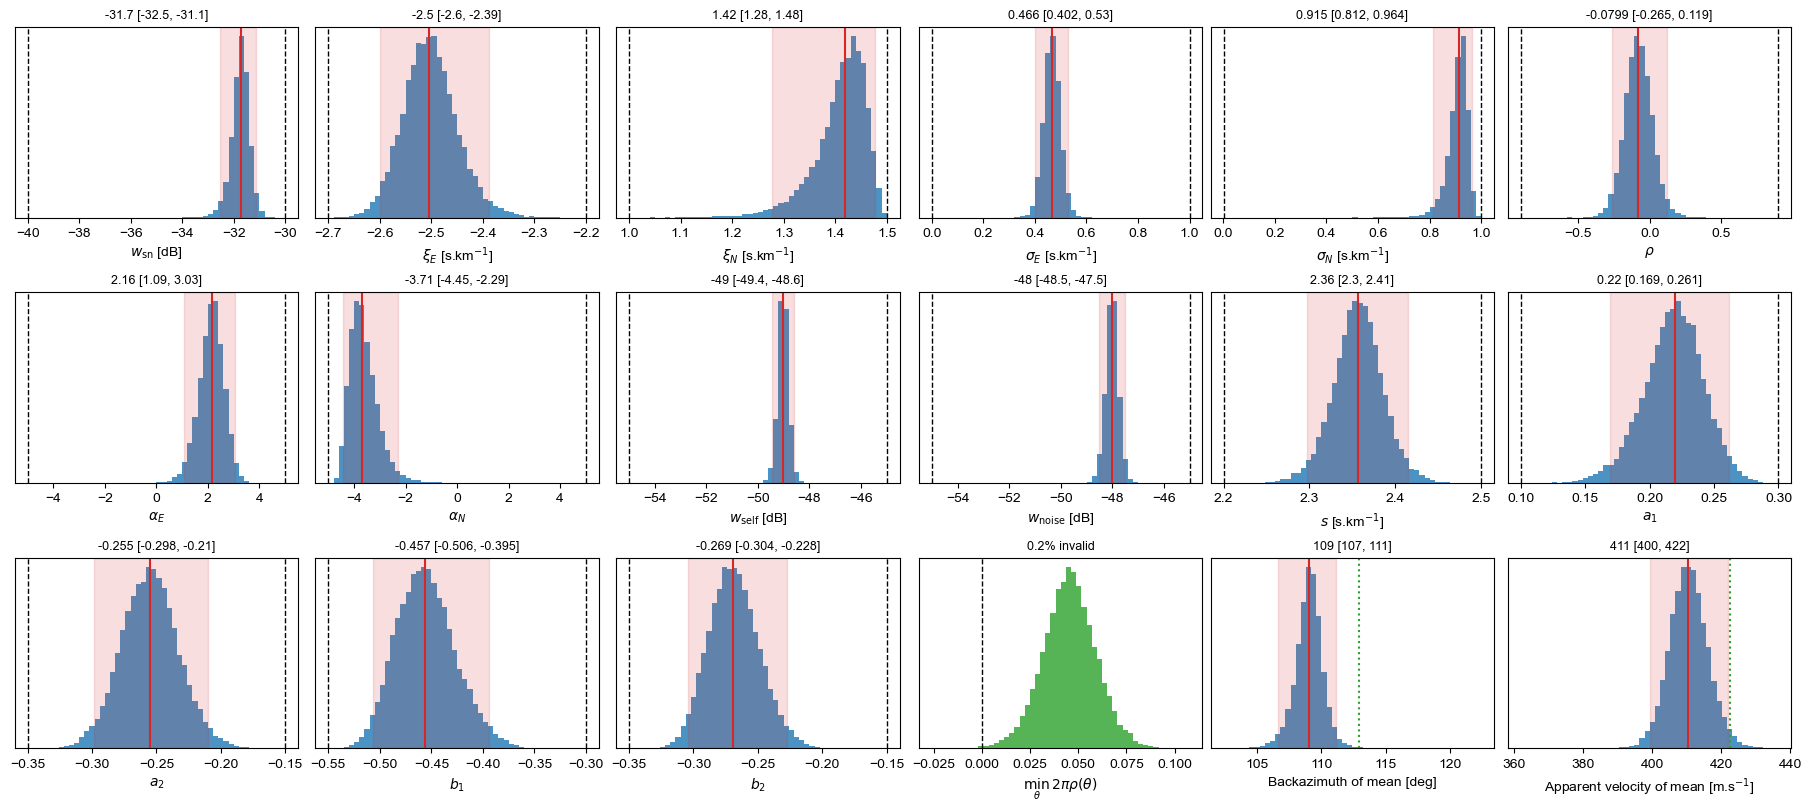

In [36]:
#__ Model vector layout __
#   [0]  w_sn      [1-2] xi_E, xi_N   [3-4] sigma_E, sigma_N   [5] rho   [6-7] alpha_E, alpha_N
#   [8]  w_self
#   [9]  w_noise   [10]  s            [11-12] a_1, a_2         [13-14] b_1, b_2
labels = [r'$w_\mathrm{sn}$ [dB]', r'$\xi_E$ [s.km$^{-1}$]', r'$\xi_N$ [s.km$^{-1}$]',
          r'$\sigma_E$ [s.km$^{-1}$]', r'$\sigma_N$ [s.km$^{-1}$]', r'$\rho$',
          r'$\alpha_E$', r'$\alpha_N$',
          r'$w_\mathrm{self}$ [dB]',
          r'$w_\mathrm{noise}$ [dB]', r'$s$ [s.km$^{-1}$]',
          r'$a_1$', r'$a_2$', r'$b_1$', r'$b_2$']
scale = np.ones(m.shape[1]) ; scale[[1, 2, 3, 4, 10]] = 1e3   # Slownesses in s.km-1

#__ Best-beam reference __
baz_bb, v_bb = 112.9, 422.6

#__ Set up figure __
fig, axes = plt.subplots(3, 6, figsize=(18, 8), constrained_layout=True)
axes = axes.ravel()

#__ Helper: histogram with median and 95% credible interval __
def hist_panel(ax, v, label, lo=None, hi=None, ref=None):
    rng_ = (lo, hi) if (lo is not None) else None
    ax.hist(v, bins=50, range=rng_, density=True, color='C0', alpha=0.8)
    if (lo is not None):
        ax.axvline(lo, color='k', ls='--', lw=1) ; ax.axvline(hi, color='k', ls='--', lw=1)
    q025, q50, q975 = np.percentile(v, [2.5, 50, 97.5])
    ax.axvline(q50, color='C3', lw=1.5)
    ax.axvspan(q025, q975, color='C3', alpha=0.15)
    if (ref is not None): ax.axvline(ref, color='C2', lw=1.5, ls=':')
    ax.set_xlabel(label) ; ax.set_yticks([])
    ax.set_title(f'{q50:.3g} [{q025:.3g}, {q975:.3g}]', fontsize=9)

#__ Parameter marginals __
for k in range(m.shape[1]):
    hist_panel(axes[k], m[:, k]*scale[k], labels[k], lower[k]*scale[k], upper[k]*scale[k])

#__ Positivity of noise azimuthal density __
theta   = np.linspace(0, 2*np.pi, 361)
basis   = np.stack([np.cos(theta), np.cos(2*theta), np.sin(theta), np.sin(2*theta)])
rho_min = (1 + 2 * m[:, 11:15] @ basis).min(axis=1)
ax = axes[15]
ax.hist(rho_min, bins=50, density=True, color='C2', alpha=0.8)
ax.axvline(0, color='k', ls='--', lw=1)
ax.set_xlabel(r'$\min_\theta\, 2\pi\rho(\theta)$') ; ax.set_yticks([])
ax.set_title(f'{100*np.mean(rho_min < 0):.1f}% invalid', fontsize=9)

#__ Skew-normal mean: xi + W delta sqrt(2/pi), delta = Omega_z alpha / sqrt(1 + alpha' Omega_z alpha) __
xi, sig, rho_c, alpha = m[:, 1:3], m[:, 3:5], m[:, 5], m[:, 6:8]
Oza   = np.stack([alpha[:,0] + rho_c*alpha[:,1], rho_c*alpha[:,0] + alpha[:,1]], axis=1)
delta = Oza / np.sqrt(1 + np.sum(alpha*Oza, axis=1))[:, None]
p_mean = xi + sig * delta * np.sqrt(2/np.pi)

#__ Backazimuth and apparent velocity of the mean __
baz = np.degrees(np.arctan2(-p_mean[:,0], -p_mean[:,1])) % 360
vel = 1 / np.linalg.norm(p_mean, axis=1)
hist_panel(axes[16], baz, 'Backazimuth of mean [deg]', ref=baz_bb)
hist_panel(axes[17], vel, r'Apparent velocity of mean [m.s$^{-1}$]', ref=v_bb)

plt.show()

### 2.2.3 Interrogate model ensemble

In [37]:
xi, sig, rho_c, alpha = m[:, 1:3], m[:, 3:5], m[:, 5], m[:, 6:8]

#__ delta = Omega_z alpha / sqrt(1 + alpha' Omega_z alpha) __
Oza   = np.stack([alpha[:,0] + rho_c*alpha[:,1], rho_c*alpha[:,0] + alpha[:,1]], axis=1)
delta = Oza / np.sqrt(1 + np.sum(alpha*Oza, axis=1))[:, None]

#__ Skew direction in slowness space [s.m-1] __
d = sig * delta

#__ Tangential (clockwise) and radial unit vectors at xi __
xi_abs = np.linalg.norm(xi, axis=1)[:, None]
t_cw   = np.stack([xi[:,1], -xi[:,0]], axis=1) / xi_abs
r_hat  = xi / xi_abs

#__ Components of the skew __
d_t = np.sum(d * t_cw, axis=1)   # > 0: clockwise
d_r = np.sum(d * r_hat, axis=1)  # > 0: towards slower apparent velocity

#__ Angular offset of the mean from xi [deg] __
dphi = np.degrees(np.sqrt(2/np.pi) * d_t / xi_abs[:, 0])

print(f'P(anti-clockwise) = {100*np.mean(d_t < 0):.3f} %')
print(f'mean offset from xi: {np.median(dphi):.2f} deg [{np.percentile(dphi,2.5):.2f}, {np.percentile(dphi,97.5):.2f}]')

P(anti-clockwise) = 99.970 %
mean offset from xi: -8.75 deg [-10.54, -6.88]
